# 02 · Modelling: churn prediction, uplift, and the business case

**Group 11 · Track 3 Project Showcase · Topic A: Customer Churn Prediction with Simple Uplift Extension**

This notebook is the end-to-end ML case study. It follows on from `01_eda.ipynb` (data exploration) and runs the real pipeline:

1. Split the data the same way every time
2. Train and compare three **classical churn models**
3. **Calibrate** the best model so its probabilities are honest
4. Explain it with **SHAP**
5. Build a **simulated** retention-offer trial (the dataset has none)
6. Train a **T-learner uplift model**
7. Compare targeting by **churn risk** vs **uplift** vs **random**
8. Turn scores into **profit** and a **business recommendation**
9. Show the **decision rules** the demo app uses
10. Check that every number matches the saved results the app reads

> **How this notebook relates to the code.** It imports the project's own functions from `ml/` (`preprocess.py`, `train_classical.py`, `simulate_treatment.py`, `train_uplift.py`), so the logic is identical to the scripts. It trains everything **in memory** and does **not** overwrite the saved models in `ml/models/`.
>
> ⚠️ **Sections 5 onward use a simulated discount trial.** The IBM Telco data never recorded who received an offer. All uplift and dollar figures illustrate the method; they are not real campaign results.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import yaml
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (ConfusionMatrixDisplay, brier_score_loss, confusion_matrix,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklift.metrics import qini_auc_score, qini_curve

warnings.filterwarnings("ignore")

# Import the project's own code from ml/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "ml"))
from preprocess import FEATURE_COLS, RANDOM_STATE, TARGET, build_preprocessor, load_clean, split_data
from train_classical import THRESHOLD, evaluate, make_models, pretty_name
from simulate_treatment import SAVE_RATE, BACKFIRE_RATE, simulate_treatment
from train_uplift import TOP_K, TLearner, base_models, cv_qini, true_gain_curve
%matplotlib inline
# (the ml/ scripts switch matplotlib to file-only mode; this turns inline charts back on)

RESULTS = PROJECT_ROOT / "ml" / "results"
PARAMS = yaml.safe_load(open(PROJECT_ROOT / "params.yaml"))
sns.set_theme(style="whitegrid")
COLORS = {"Logistic Regression": "#8C8C8C", "Random Forest": "#C44E52", "XGBoost": "#4C72B0",
          "Churn risk": "#C44E52", "Uplift (T-learner)": "#8172B3", "Random": "#8C8C8C"}
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\Devansh Datta\Desktop\PROECTS\amlproject\churn-uplift


## 1. Data and the train/test split

We use the cleaned data from `01_eda.ipynb` / `ml/preprocess.py` (blank `TotalCharges` set to 0, "No internet service" merged into "No", `Churn` as 1/0).

The split is **80% train / 20% test, stratified on churn** with a fixed seed. Every model in this notebook is judged on the **same 1,409 test customers**, which none of them see during training.

In [2]:
df = load_clean()
train, test = split_data(df)
X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_test, y_test = test[FEATURE_COLS], test[TARGET]

print(f"All customers: {len(df):,}   features: {len(FEATURE_COLS)}")
print(f"Train: {len(train):,}  churn rate {y_train.mean():.1%}")
print(f"Test:  {len(test):,}  churn rate {y_test.mean():.1%}")

All customers: 7,043   features: 19
Train: 5,634  churn rate 26.5%
Test:  1,409  churn rate 26.5%


The data is **imbalanced**: about 3 stayers for every leaver. A model that predicts "everyone stays" would be 73% accurate and completely useless, so we don't use accuracy as the headline metric.

## 2. Three classical churn models

| Model | Idea | Why include it |
|---|---|---|
| **Logistic Regression** | weighted sum of features → probability | simple, explainable baseline |
| **Random Forest** | 300 decision trees vote | captures interactions, robust |
| **XGBoost** | trees built one after another, each fixing the last one's errors | usually strongest on tabular data |

Each model sits inside a scikit-learn **Pipeline**: `[one-hot encode + scale] → [model]`. The encoder and scaler learn only from the training rows, so nothing leaks from the test set.

**Class imbalance** is handled with class weights (`class_weight="balanced"`, or `scale_pos_weight` for XGBoost): a missed leaver costs about 3× more during training.

**Metrics** (test set, threshold 0.5):
- **ROC-AUC**: how well the model *ranks* leavers above stayers (threshold-free; 0.5 = random, 1 = perfect)
- **Recall**: of customers who really left, the share we flagged. This matters most for retention, because a missed leaver is lost revenue
- **Precision**: of customers we flagged, the share who really left
- **5-fold CV AUC** on the training data, to check the result is stable and not luck

In [3]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results, pipelines, probs = {}, {}, {}
for name, model in make_models(pos_weight).items():
    pipe = Pipeline([("preprocess", build_preprocessor()), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    m = evaluate(y_test, prob)
    m["cv_auc_mean"], m["cv_auc_std"] = cv_auc.mean(), cv_auc.std()
    results[name], pipelines[name], probs[name] = m, pipe, prob

leaderboard = pd.DataFrame(results).T[["roc_auc", "precision", "recall", "f1", "cv_auc_mean", "cv_auc_std"]]
leaderboard.round(3)

,roc_auc,precision,recall,f1,cv_auc_mean,cv_auc_std
Logistic Regression,0.842,0.505,0.786,0.615,0.846,0.012
Random Forest,0.845,0.537,0.794,0.641,0.848,0.011
XGBoost,0.841,0.523,0.775,0.624,0.845,0.011


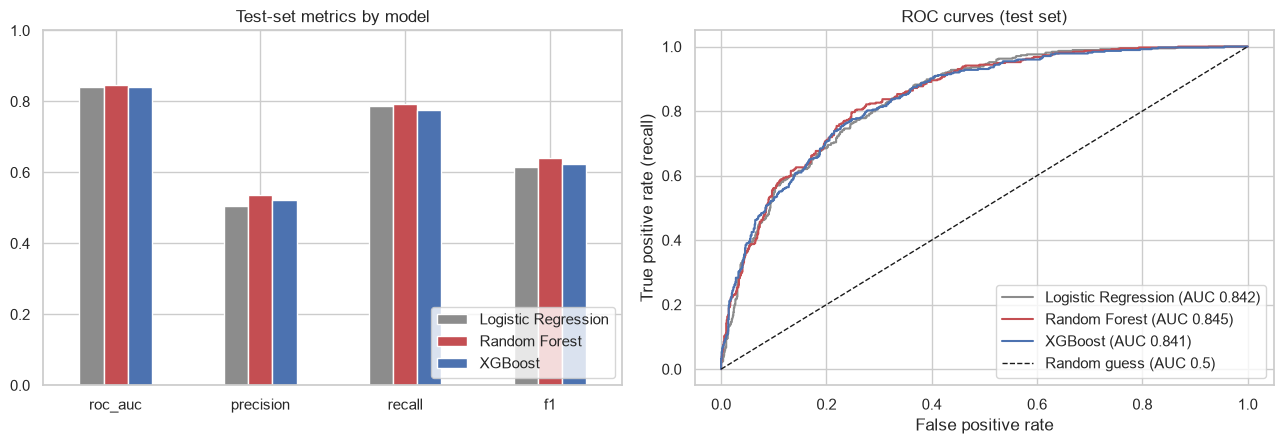

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

leaderboard[["roc_auc", "precision", "recall", "f1"]].T.plot.bar(
    ax=axes[0], color=[COLORS[n] for n in leaderboard.index], rot=0)
axes[0].set_title("Test-set metrics by model"); axes[0].set_ylim(0, 1); axes[0].legend(loc="lower right")

for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {results[name]['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC 0.5)")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curves (test set)")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

In [5]:
best_name = max(results, key=lambda n: results[n]["roc_auc"])
best_pipe = pipelines[best_name]
spread = leaderboard["roc_auc"].max() - leaderboard["roc_auc"].min()
print(f"Best model by test ROC-AUC: {best_name} ({results[best_name]['roc_auc']:.3f})")
print(f"Spread between best and worst model: {spread:.3f} AUC")
print(f"CV standard deviation of the best model: {results[best_name]['cv_auc_std']:.3f}")

Best model by test ROC-AUC: Random Forest (0.845)
Spread between best and worst model: 0.004 AUC
CV standard deviation of the best model: 0.011


**Reading the result.** Random Forest has the highest test ROC-AUC, but all three models are within about 0.004 of each other, which is smaller than the cross-validation spread. The honest conclusion: **the information in the data, not the choice of algorithm, limits performance.** We keep Random Forest (best AUC and best recall) and don't spend effort on heavy tuning.

### Confusion matrix of the chosen model

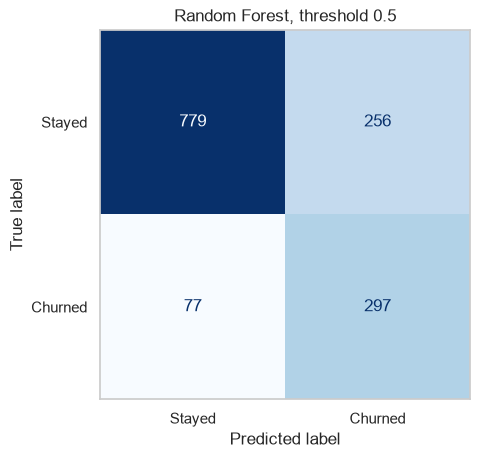

Leavers caught: 297   missed: 77   false alarms: 256   stayers correctly left alone: 779


In [6]:
cm = confusion_matrix(y_test, (probs[best_name] >= THRESHOLD).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{best_name}, threshold {THRESHOLD}"); plt.grid(False); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Leavers caught: {tp}   missed: {fn}   false alarms: {fp}   stayers correctly left alone: {tn}")

The model catches about 4 in 5 leavers at the cost of some false alarms. For retention that trade-off is right: a false alarm costs at most one offer, a missed leaver costs a year of revenue.

## 3. Calibration: making the probabilities honest

Class weights help the model find leavers, but they inflate its probabilities. The demo app shows each customer's **chance of staying**, so the number must mean what it says.

We wrap the chosen pipeline in `CalibratedClassifierCV` with **Platt scaling** (`method="sigmoid"`, 5 folds on the training data). It re-maps scores with a small logistic curve: **the ranking is unchanged** (same AUC), only the scale is corrected.

,mean predicted churn,actual churn rate,Brier score (lower = better),ROC-AUC
before (class-weighted),0.3937,0.2654,0.1580,0.8455
after calibration,0.2672,0.2654,0.1363,0.8459


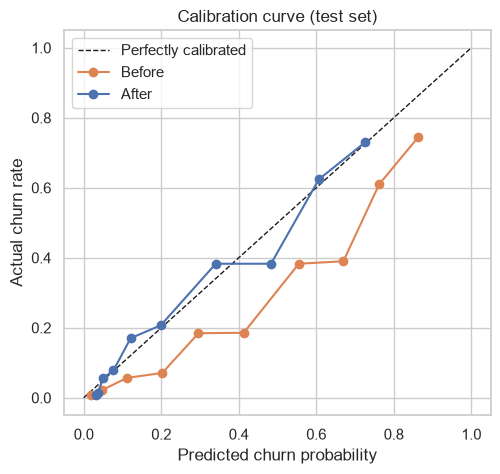

In [7]:
calibrated = CalibratedClassifierCV(clone(best_pipe), method="sigmoid", cv=5).fit(X_train, y_train)
raw_prob, cal_prob = probs[best_name], calibrated.predict_proba(X_test)[:, 1]

cal_table = pd.DataFrame({
    "mean predicted churn": [raw_prob.mean(), cal_prob.mean()],
    "actual churn rate": [y_test.mean()] * 2,
    "Brier score (lower = better)": [brier_score_loss(y_test, raw_prob), brier_score_loss(y_test, cal_prob)],
    "ROC-AUC": [roc_auc_score(y_test, raw_prob), roc_auc_score(y_test, cal_prob)],
}, index=["before (class-weighted)", "after calibration"])
display(cal_table.round(4))

plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
for label, p, c in [("Before", raw_prob, "#DD8452"), ("After", cal_prob, "#4C72B0")]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac, "o-", color=c, label=label)
plt.xlabel("Predicted churn probability"); plt.ylabel("Actual churn rate")
plt.title("Calibration curve (test set)"); plt.legend(); plt.show()

Before calibration the model predicted ~39% churn on average against a real 26.5%. After Platt scaling the average matches reality, the Brier score improves, and ROC-AUC is unchanged. **The calibrated model is the one the app uses.**

## 4. Explaining the model with SHAP

SHAP splits every prediction into **one contribution per feature** (for example, "month-to-month contract pushed this customer +12 points towards leaving"). Averaging the size of those contributions gives global importance; each dot in the beeswarm is one test customer.

We explain the uncalibrated Random Forest: calibration rescales the output but doesn't change which features drive it.

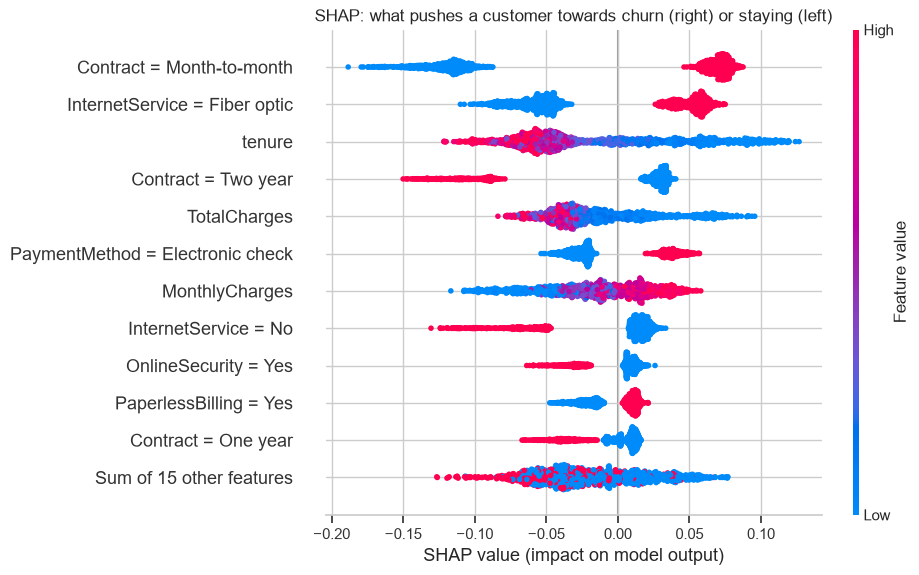

In [8]:
pre, rf = best_pipe.named_steps["preprocess"], best_pipe.named_steps["model"]
X_test_t = pre.transform(X_test)
sv = shap.TreeExplainer(rf)(X_test_t)
sv.feature_names = [pretty_name(f) for f in pre.get_feature_names_out()]
if sv.values.ndim == 3:          # Random Forest returns one set per class: keep "churn"
    sv = sv[:, :, 1]
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP: what pushes a customer towards churn (right) or staying (left)"); plt.show()

In [9]:
mean_abs = np.abs(sv.values).mean(axis=0)
drivers = pd.DataFrame({"feature": sv.feature_names, "mean |SHAP|": mean_abs})
drivers["direction"] = [
    "increases churn" if np.corrcoef(sv.data[:, i], sv.values[:, i])[0, 1] > 0 else "decreases churn"
    for i in range(len(drivers))]
drivers.sort_values("mean |SHAP|", ascending=False).head(10).round(4).reset_index(drop=True)

,feature,mean |SHAP|,direction
0,Contract = Month-to-month,0.0933,increases churn
1,InternetService = Fiber optic,0.0557,increases churn
2,tenure,0.0533,decreases churn
3,Contract = Two year,0.0476,decreases churn
4,TotalCharges,0.0336,decreases churn
5,PaymentMethod = Electronic check,0.0307,increases churn
6,MonthlyCharges,0.0305,increases churn
7,InternetService = No,0.0283,decreases churn
8,OnlineSecurity = Yes,0.0162,decreases churn
9,PaperlessBilling = Yes,0.0152,increases churn


The drivers agree with the EDA: **month-to-month contracts, fiber internet and short tenure** push customers out; **long tenure and two-year contracts** keep them. In the app, each customer's three biggest positive and negative SHAP contributions become the plain-English *"Why they might leave / stay"* lists.

## 5. Why a churn model isn't enough: uplift

A churn model answers *who will leave*. A retention budget needs *whose decision we can change*. Every customer falls into one of four groups:

| | Would **leave** without an offer | Would **stay** without an offer |
|---|---|---|
| **Stays** with an offer | **Persuadables**: the only group the discount works on | **Sure things**: the discount is wasted |
| **Leaves** with an offer | **Lost causes**: the discount is wasted | **Sleeping dogs**: contacting them backfires |

Ranking by churn risk puts persuadables *and* lost causes at the top. An **uplift model** estimates, per customer, how much the offer changes the chance of staying, so it can tell them apart.

### 5.1 The simulated retention trial ⚠️

Uplift needs data on who got an offer. Telco has none, so `ml/simulate_treatment.py` creates a **randomised trial**:

1. Each customer gets the offer with probability 50% (like a fair A/B test).
2. Customers **without** the offer keep their real outcome.
3. Customers **with** the offer may change outcome according to **assumed** rules per segment:

In [10]:
assumptions = pd.DataFrame({
    "rule": ["Two-year contract AND tenure > 48 months",
             "Fiber AND electronic check AND bill > $90",
             "Month-to-month AND tenure ≤ 12 months",
             "Any other month-to-month",
             "Any other 1- or 2-year contract"],
    "assumed save rate (of real leavers)": [SAVE_RATE[s] for s in ["sleeping_dog", "lost_cause", "persuadable", "m2m_other", "contract"]],
    "assumed backfire rate (of real stayers)": [BACKFIRE_RATE.get(s, 0.0) for s in ["sleeping_dog", "lost_cause", "persuadable", "m2m_other", "contract"]],
}, index=["sleeping_dog", "lost_cause", "persuadable", "m2m_other", "contract"])
assumptions

,rule,assumed save rate (of real leavers),assumed backfire rate (of real stayers)
sleeping_dog,Two-year contract AND tenure > 48 months,0.00,0.03
lost_cause,Fiber AND electronic check AND bill > $90,0.05,0.00
persuadable,Month-to-month AND tenure ≤ 12 months,0.40,0.00
m2m_other,Any other month-to-month,0.20,0.00
contract,Any other 1- or 2-year contract,0.05,0.00


In [11]:
sim = simulate_treatment(df)
g = sim.groupby("segment")
seg = pd.DataFrame({
    "customers": g.size(),
    "real churn rate": g["Churn"].mean(),
    "churn without offer": sim[sim.treatment == 0].groupby("segment")["churn_sim"].mean(),
    "churn with offer": sim[sim.treatment == 1].groupby("segment")["churn_sim"].mean(),
})
seg["observed effect (pts)"] = (seg["churn without offer"] - seg["churn with offer"]) * 100
display(seg.loc[["persuadable", "m2m_other", "lost_cause", "contract", "sleeping_dog"]].round(3))

ctrl, trt = sim.loc[sim.treatment == 0, "churn_sim"].mean(), sim.loc[sim.treatment == 1, "churn_sim"].mean()
print(f"Treated {sim.treatment.sum():,} / control {(1 - sim.treatment).sum():,}")
print(f"Overall churn without offer {ctrl:.1%}, with offer {trt:.1%} -> average effect {100 * (ctrl - trt):.1f} points")

,customers,real churn rate,churn without offer,churn with offer,observed effect (pts)
segment,,,,,
persuadable,1842,0.492,0.483,0.303,17.963
m2m_other,1495,0.296,0.311,0.215,9.569
lost_cause,712,0.492,0.468,0.486,-1.865
contract,1731,0.074,0.071,0.075,-0.370
sleeping_dog,1263,0.033,0.028,0.059,-3.090


Treated 3,527 / control 3,516
Overall churn without offer 26.0%, with offer 20.5% -> average effect 5.5 points


Because **we** wrote the rules, we also know each customer's **true effect** (`true_effect`: expected customers saved by contacting them). A real company never has this. Here it lets us score every targeting strategy exactly. It is used **only for evaluation**, never as a model input.

## 6. The T-learner uplift model

**T-learner = two models:**
- **Model T** learns from customers who **got** the offer → P(stay | offer)
- **Model C** learns from customers who **didn't** → P(stay | no offer)
- **Uplift = P(stay | offer) − P(stay | no offer)**: positive helps, ~0 no effect, negative backfires

We try two base learners and choose between them with **5-fold cross-validated Qini on the training data only**. Qini is the standard uplift metric: how many *extra* customers stay as you contact more people in score order.

In [12]:
sim_train, sim_test = split_data(sim)          # same customers as Section 1
Xs_train, Xs_test = sim_train[FEATURE_COLS], sim_test[FEATURE_COLS]
ys_train, ys_test = 1 - sim_train["churn_sim"], 1 - sim_test["churn_sim"]   # 1 = stayed
t_train, t_test = sim_train["treatment"], sim_test["treatment"]

cv_scores = {name: cv_qini(base, Xs_train, ys_train, t_train) for name, base in base_models().items()}
chosen = max(cv_scores, key=cv_scores.get)
display(pd.Series(cv_scores, name="5-fold CV Qini (train)").round(4).to_frame())
print("Chosen base learner:", chosen)

,5-fold CV Qini (train)
T-learner (Logistic Regression),0.0487
T-learner (XGBoost),0.0408


Chosen base learner: T-learner (Logistic Regression)


Logistic Regression wins: the uplift signal is small and noisy (it's a *difference* of two predictions), and the simpler model generalises better than XGBoost here.

## 7. Which ranking saves more customers?

The question from the brief: **classical churn model vs basic uplift.** With a budget to contact the **top 20%** of test customers, we rank them three ways and count the customers each ranking truly saves:

- **Churn risk**: the calibrated Random Forest from Section 3
- **Uplift**: the chosen T-learner
- **Random**: the baseline any model must beat

In [13]:
tlearner = TLearner(base_models()[chosen]).fit(Xs_train, ys_train, t_train)
rankings = {
    "Churn risk": calibrated.predict_proba(Xs_test)[:, 1],
    "Uplift (T-learner)": tlearner.predict_uplift(Xs_test),
    "Random": np.random.default_rng(RANDOM_STATE).random(len(sim_test)),
}
true_effect = sim_test["true_effect"].to_numpy()
k = int(round(TOP_K * len(sim_test)))

rows = {}
for name, s in rankings.items():
    top = np.argsort(-s)[:k]
    segs = sim_test.iloc[top]["segment"].value_counts()
    rows[name] = {
        "customers truly saved (top 20%)": round(true_effect[top].sum(), 1),
        "Qini AUC": qini_auc_score(ys_test, s, t_test),
        "persuadables contacted": int(segs.get("persuadable", 0)),
        "lost causes contacted": int(segs.get("lost_cause", 0)),
        "sleeping dogs contacted": int(segs.get("sleeping_dog", 0)),
    }
comparison = pd.DataFrame(rows).T
count_cols = ["persuadables contacted", "lost causes contacted", "sleeping dogs contacted"]
comparison[count_cols] = comparison[count_cols].astype(int)
best_possible = np.sort(true_effect)[::-1][:k].sum()
display(comparison.round(3))
print(f"Top 20% = {k} customers. A perfect ranking would save {best_possible:.1f}.")

,customers truly saved (top 20%),Qini AUC,persuadables contacted,lost causes contacted,sleeping dogs contacted
Churn risk,58.2,0.040,188,56,0
Uplift (T-learner),50.9,0.028,177,17,0
Random,19.8,0.002,86,27,48


Top 20% = 282 customers. A perfect ranking would save 94.9.


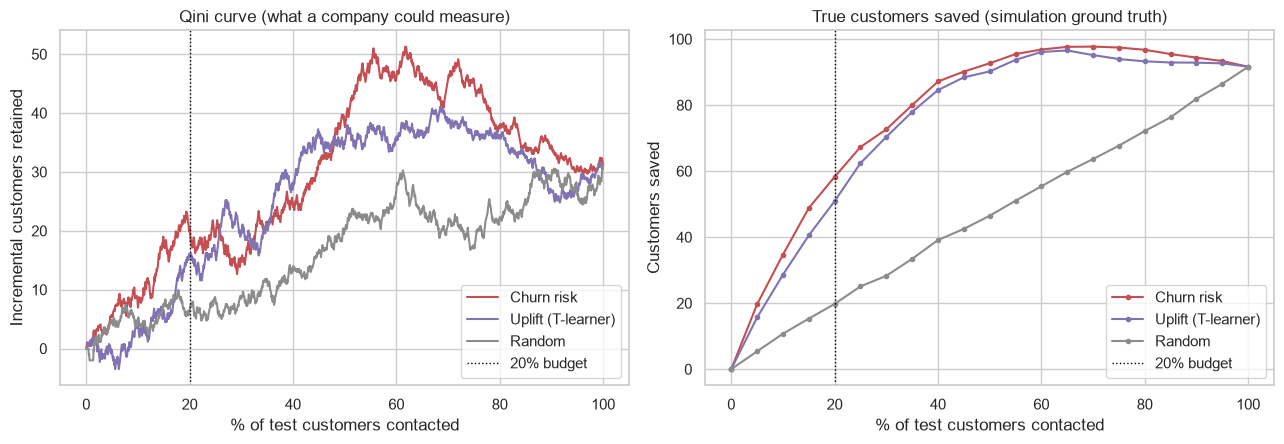

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, s in rankings.items():
    x, yq = qini_curve(ys_test, s, t_test)
    axes[0].plot(x / len(sim_test) * 100, yq, color=COLORS[name], label=name)
    fr, gain = true_gain_curve(s, true_effect)
    axes[1].plot(fr * 100, gain, "o-", ms=3, color=COLORS[name], label=name)
for ax, title, ylabel in [(axes[0], "Qini curve (what a company could measure)", "Incremental customers retained"),
                          (axes[1], "True customers saved (simulation ground truth)", "Customers saved")]:
    ax.axvline(TOP_K * 100, ls=":", color="black", lw=1, label="20% budget")
    ax.set(xlabel="% of test customers contacted", ylabel=ylabel, title=title); ax.legend()
plt.tight_layout(); plt.show()

**Result.** Both models beat random by roughly **3×**. **Churn-risk ranking saves the most customers** at the 20% budget, with uplift close behind.

**Why didn't uplift win?** In this simulation the persuadables (new month-to-month customers) are *also* the highest-risk customers, so ranking by risk already finds most of them. Uplift does what it promises: it contacts **far fewer lost causes**. But its estimates are noisier, because they are the difference between two models trained on half the data each. A Logistic Regression T-learner also can't learn the AND-rules that define the lost-cause segment.

This conclusion depends on the simulation's assumptions; with real trial data the result could differ.

## 8. From scores to money

**Business assumptions** (`params.yaml`; demo values, easy to change):
- each offer costs **${offer}**, paid for every contacted customer
- keeping a customer is worth **{months} months** of their bill

For each ranking and each campaign size (10%, 20% … 100% contacted):

    cost         = customers contacted × offer cost
    value saved  = Σ true_effect × monthly bill × 12   (over contacted customers)
    profit       = value saved − cost

In [15]:
biz = PARAMS["business"]
customer_value = (sim_test["MonthlyCharges"] * biz["clv_months"]).to_numpy()
dollar_effect = true_effect * customer_value

roi_rows = []
for name, s in rankings.items():
    order = np.argsort(-s)
    for pct in biz["target_percents"]:
        n = int(round(pct / 100 * len(sim_test)))
        cost = n * biz["offer_cost"]
        value = dollar_effect[order[:n]].sum()
        roi_rows.append({"method": name, "percent": pct, "contacted": n, "profit": value - cost,
                         "ROI": (value - cost) / cost})
roi_test = pd.DataFrame(roi_rows)
roi_test.pivot(index="percent", columns="method", values="profit").round(0)

method,Churn risk,Random,Uplift (T-learner)
percent,,,
10,25486.0,1623.0,17187.0
20,37264.0,2383.0,28476.0
30,40705.0,1844.0,37010.0
40,42459.0,2967.0,41369.0
50,39283.0,1916.0,37785.0
60,33957.0,1237.0,33036.0
70,26619.0,640.0,25422.0
80,18441.0,-703.0,17331.0
90,9435.0,-78.0,9762.0


### The whole customer base (what the demo app shows)

The app scores **all 7,043 customers** with **out-of-fold** predictions (`ml/score_customers.py`): customers are split into 5 groups and each group is scored by models trained on the other 4, so no customer is scored by a model that saw them. That run takes a few minutes, so we load its saved output here.

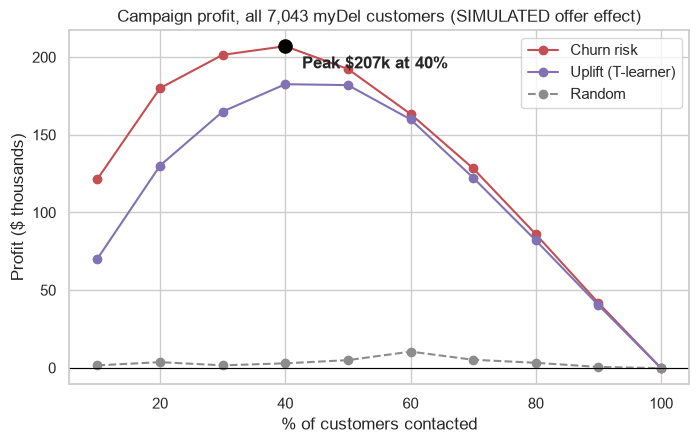

,percent,contacted,profit,roi
method,,,,
Churn risk,40,2817,207060,1.47
Random,60,4226,10417,0.05
Uplift (T-learner),40,2817,182582,1.30


In [16]:
mydel = pd.DataFrame(json.load(open(RESULTS / "mydel_roi.json"))["table"])
curve = mydel.pivot(index="percent", columns="method", values="profit")

plt.figure(figsize=(8, 4.6))
for name in ["Churn risk", "Uplift (T-learner)", "Random"]:
    plt.plot(curve.index, curve[name] / 1000, "o-", color=COLORS[name], label=name,
             ls="--" if name == "Random" else "-")
peak = mydel.loc[mydel["profit"].idxmax()]
plt.scatter([peak.percent], [peak.profit / 1000], s=90, color="black", zorder=5)
plt.annotate(f"Peak ${peak.profit / 1000:,.0f}k at {peak.percent}%", (peak.percent, peak.profit / 1000),
             textcoords="offset points", xytext=(12, -16), fontweight="bold")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("% of customers contacted"); plt.ylabel("Profit ($ thousands)")
plt.title("Campaign profit, all 7,043 myDel customers (SIMULATED offer effect)"); plt.legend(); plt.show()

peaks = mydel.loc[mydel.groupby("method")["profit"].idxmax(), ["method", "percent", "contacted", "profit", "roi"]]
peaks.set_index("method").round(2)

### Business recommendation

1. **Target by churn risk and contact the top ~40%** (≈2,800 customers): about **$207k** profit over a year in this simulation, versus about $183k for uplift ranking and almost nothing for random picks.
2. **Don't contact everyone.** Past ~40% the extra offers mostly go to sure things, and profit falls to roughly zero at 100%.
3. **Use the uplift model as a filter, not the ranking:** skip customers it flags as sleeping dogs (negative uplift).
4. **Run a real A/B test before trusting uplift scores**, because the offer effects here are simulated.

## 9. The decision rules in the demo app

`backend/app/model_service.py` turns the two scores into one of four actions per customer, checked in this order (thresholds from `params.yaml`):

1. uplift < −0.02 → **Don't contact** (sleeping dog; tiny negatives are treated as noise)
2. churn probability < 30% → **No action needed** (they'll probably stay)
3. expected profit = uplift × customer value − $50 > 0 → **Send the discount**
4. otherwise → **Call them instead** (high risk, but money isn't the fix)

In [17]:
dec = PARAMS["decision"]

def decide(churn_prob, uplift, customer_value):
    if uplift < -dec["backfire_margin"]:
        return "Do not contact"
    if churn_prob < dec["low_risk_threshold"]:
        return "No action needed"
    if uplift * customer_value - biz["offer_cost"] > 0:
        return "Send retention offer"
    return "Try non-discount retention"

customers = pd.read_csv(PROJECT_ROOT / "backend" / "data" / "mydel_customers.csv")
customers["action"] = [decide(p, u, m * biz["clv_months"]) for p, u, m in
                       zip(customers["churn_prob"], customers["uplift_score"], customers["MonthlyCharges"])]
customers["action"].value_counts().to_frame("customers")

,customers
action,
No action needed,3460
Send retention offer,2269
Do not contact,1002
Try non-discount retention,312


## 10. Reproducibility check

Everything above was retrained from scratch in this notebook. These checks confirm it matches the saved results in `ml/results/`, which are the numbers the demo app displays.

In [18]:
saved_cls = json.load(open(RESULTS / "classical_metrics.json"))
saved_upl = json.load(open(RESULTS / "uplift_metrics.json"))

checks = []
for name in results:
    checks.append((f"{name} ROC-AUC", results[name]["roc_auc"], saved_cls["models"][name]["roc_auc"]))
checks.append(("Best model", best_name, saved_cls["best_model"]))
checks.append(("Calibrated mean churn", cal_prob.mean(), saved_cls["calibration"]["after"]["mean_predicted"]))
checks.append(("Chosen uplift learner", chosen, saved_upl["chosen_uplift_model"]))
checks.append(("Uplift: saved in top 20%", rows["Uplift (T-learner)"]["customers truly saved (top 20%)"],
               saved_upl["methods"][chosen]["true_saved_top20"]))
checks.append(("Churn risk: saved in top 20%", rows["Churn risk"]["customers truly saved (top 20%)"],
               saved_upl["methods"]["Churn risk (Random Forest)"]["true_saved_top20"]))
checks.append(("Best possible in top 20%", round(best_possible, 1), saved_upl["best_possible_saved_top20"]))

def same(a, b):
    return a == b if isinstance(a, str) else abs(float(a) - float(b)) < 1e-3 + 1e-3 * abs(float(b))

report = pd.DataFrame([(n, a, b, "✓" if same(a, b) else "✗") for n, a, b in checks],
                      columns=["check", "this notebook", "saved results", "match"])
display(report)
assert report["match"].eq("✓").all(), "Some results differ from ml/results/"
print("All checks pass: the notebook reproduces the saved results.")

,check,this notebook,saved results,match
0,Logistic Regression ROC-AUC,0.841796,0.8418,✓
1,Random Forest ROC-AUC,0.845479,0.8455,✓
2,XGBoost ROC-AUC,0.841488,0.8415,✓
3,Best model,Random Forest,Random Forest,✓
4,Calibrated mean churn,0.267155,0.2672,✓
5,Chosen uplift learner,T-learner (Logistic Regression),T-learner (Logistic Regression),✓
6,Uplift: saved in top 20%,50.9,50.9,✓
7,Churn risk: saved in top 20%,58.2,58.2,✓
8,Best possible in top 20%,94.9,94.9,✓


All checks pass: the notebook reproduces the saved results.


## 11. Conclusions and limitations

**What we found**
- Three classical models reach **ROC-AUC ≈ 0.84–0.85** and recall ≈ 0.79. Random Forest is chosen, but the models are statistically tied; the data limits performance.
- **Calibration** fixed inflated probabilities (≈39% → 26.7% average predicted churn) without changing the ranking.
- **SHAP** confirms the EDA: contract type, tenure and fiber internet drive churn.
- With a 20% budget, **churn-risk ranking saved the most customers**; the **T-learner uplift model** came close and wasted far fewer offers on lost causes. Both beat random by ~3×.
- **Recommendation:** contact the top ~40% by churn risk, filter out predicted sleeping dogs, and validate with a real A/B test.

**Limitations**
- ⚠️ The offer and its effects are **simulated**; all uplift and dollar results demonstrate the method, not real customer behaviour.
- The simulation's assumptions favour churn-risk ranking (the offer mainly helps real leavers), so *"risk beats uplift"* partly follows from the design.
- A Logistic Regression T-learner can't learn interaction rules such as *fiber AND e-check AND bill > $90*.
- $50 per offer and 12 months of value are assumptions; changing them in `params.yaml` moves the optimal campaign size.
- One snapshot of data: the model predicts *whether*, not *when*, a customer leaves.